# 08 Option 1: one growth curve for every video

In [1]:
"""Option 1 for taking video age out of views: one growth curve G(age), learned from every video's day-to-day
growth in the daily log, then used to move every video's views to a common age (day REF_AGE).
Evaluation (same in notebooks 08-10): projection 14 days ahead from one snapshot (held out by video and by
channel), bias by start age, residual age trend after normalizing, and trait signal on the tagged videos."""
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.path.abspath("../src"))
import config
from traits import get_traits

warnings.filterwarnings("ignore")

FIRST_SNAPSHOT = "2026-10-15"
SNAPSHOT_DATE = "2026-11-13"
REF_AGE = 30
KNOTS = np.array(list(range(1, 31)) + [35, 40, 45, 52, 60, 70, 80, 90, 105, 120, 140, 160, 180, 210, 240, 270, 300, 340, 400], dtype=float)
SMOOTHING_GRID = [0, 0.01, 0.1, 1, 10, 100]
HORIZON = 14
START_AGE_BANDS = [1, 3, 7, 14, 30, 60, 120, 400]
SHORTS_MAX_SECONDS = 60
N_FOLDS = 5
N_REPEATS = 3
N_SHUFFLES = 10
ALPHAS = np.logspace(-2, 4, 25)
SEED = 585
RED, GRAY, DARK, MUTED = "#990000", "#BDBDBD", "#222222", "#6B6B6B"
FIG_DIR = "../docs/figures"
ANALYSIS_DIR = "../data/analysis"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(ANALYSIS_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.family": "Arial", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888888", "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555"})
rng = np.random.default_rng(SEED)
client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)

## Every snapshot of every video

In [2]:
"""One row per video per snapshot day (Oct 15 one-time pull, then daily from Oct 21), every video on the sheet's
channels, not only the tagged ones. Deleted or private videos are left out."""
df_panel = client.query(f"""
SELECT s.video_id, s.channel_id, c.snippet_title AS channel_title, s.snapshot_date, s.snapshot_at, s.age_days,
       s.view_count, v.duration_seconds
FROM youtube.video_daily_snapshots s
JOIN youtube.videos v ON v.id = s.video_id
JOIN youtube.channels c ON c.id = s.channel_id
WHERE s.snapshot_date BETWEEN '{FIRST_SNAPSHOT}' AND '{SNAPSHOT_DATE}' AND s.is_available
""").to_dataframe().sort_values(["video_id", "snapshot_at"]).reset_index(drop=True)
df_panel["snapshot_date"] = pd.to_datetime(df_panel["snapshot_date"])
df_panel["lv"] = np.log1p(df_panel["view_count"].astype(float))
print(f"{len(df_panel):,} rows, {df_panel['video_id'].nunique():,} videos, {df_panel['channel_id'].nunique()} channels, "
      f"{df_panel['snapshot_date'].nunique()} snapshot days")
df_panel.head()

325,025 rows, 14,068 videos, 52 channels, 24 snapshot days


,video_id,channel_id,channel_title,snapshot_date,snapshot_at,age_days,view_count,duration_seconds,lv
0,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,triple j,2026-10-15,2026-10-15 05:56:42.000000+00:00,76.164365,16163,34.0,9.690542
1,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,triple j,2026-10-21,2026-10-21 19:48:05.479667+00:00,82.741719,16243,34.0,9.695479
2,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,triple j,2026-10-22,2026-10-22 14:27:40.953275+00:00,83.519212,16248,34.0,9.695787
3,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,triple j,2026-10-23,2026-10-23 14:10:29.789418+00:00,84.507278,16253,34.0,9.696094
4,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,triple j,2026-10-24,2026-10-24 13:13:46.696406+00:00,85.467890,16258,34.0,9.696402


In [3]:
df_days = df_panel.groupby("snapshot_date").agg(videos=("video_id", "size"), first_pull=("snapshot_at", "min"),
                                                median_age=("age_days", "median")).reset_index()
df_days.head(10)

,snapshot_date,videos,first_pull,median_age
0,2026-10-15,12024,2026-10-15 05:56:42.000000+00:00,181.116871
1,2026-10-21,13187,2026-10-21 19:48:05.479667+00:00,183.074878
2,2026-10-22,13215,2026-10-22 14:27:40.953275+00:00,183.326226
3,2026-10-23,13255,2026-10-23 14:10:29.789418+00:00,183.921120
4,2026-10-24,13289,2026-10-24 13:13:46.696406+00:00,184.318017
5,2026-10-25,13320,2026-10-25 13:39:44.230675+00:00,184.967665
6,2026-10-26,13359,2026-10-26 16:02:15.676668+00:00,185.828202
7,2026-10-27,13398,2026-10-27 15:16:05.413428+00:00,186.360138
8,2026-10-28,13440,2026-10-28 15:52:18.179322+00:00,186.970361
9,2026-10-29,13487,2026-10-29 15:58:55.386796+00:00,187.249067


## Day-to-day pairs

In [4]:
"""Consecutive snapshots of the same video, starting at age >= 1 day and above 0 views. Most pairs are 1 day apart;
the Oct 15 -> Oct 21 pull is a 6-day pair, and the missed Nov 8 run makes a 2-day pair."""
df_panel["lv_prev"] = df_panel.groupby("video_id")["lv"].shift()
df_panel["age_prev"] = df_panel.groupby("video_id")["age_days"].shift()
df_pairs = df_panel[(df_panel["lv_prev"] > 0) & (df_panel["age_prev"] >= 1)].reset_index(drop=True)
df_pairs["gap_days"] = df_pairs["age_days"] - df_pairs["age_prev"]
df_pairs["growth"] = df_pairs["lv"] - df_pairs["lv_prev"]
print(f"{len(df_pairs):,} pairs from {df_pairs['video_id'].nunique():,} videos")
print(df_pairs["gap_days"].round().value_counts().sort_index().head(8))
df_pairs[["video_id", "channel_title", "age_prev", "age_days", "gap_days", "lv_prev", "lv", "growth"]].head()

310,041 pairs from 13,980 videos
gap_days
1.0    284223
2.0     13795
3.0         1
6.0        30
7.0     11992
Name: count, dtype: int64


,video_id,channel_title,age_prev,age_days,gap_days,lv_prev,lv,growth
0,--2mIdgIduE,triple j,76.164365,82.741719,6.577353,9.690542,9.695479,0.004937
1,--2mIdgIduE,triple j,82.741719,83.519212,0.777494,9.695479,9.695787,0.000308
2,--2mIdgIduE,triple j,83.519212,84.507278,0.988065,9.695787,9.696094,0.000308
3,--2mIdgIduE,triple j,84.507278,85.467890,0.960612,9.696094,9.696402,0.000308
4,--2mIdgIduE,triple j,85.467890,86.485917,1.018027,9.696402,9.696586,0.000184


## Fit the curve

In [5]:
def basis(ages):
    """Linear-interpolation weights of each age on KNOTS, without the day-1 column (G(1) = 0 by definition)."""
    ages = np.clip(np.asarray(ages, dtype=float), KNOTS[0], KNOTS[-1])
    upper = np.clip(np.searchsorted(KNOTS, ages, side="right"), 1, len(KNOTS) - 1)
    weight = (ages - KNOTS[upper - 1]) / (KNOTS[upper] - KNOTS[upper - 1])
    out = np.zeros((len(ages), len(KNOTS)))
    out[np.arange(len(ages)), upper - 1] = 1 - weight
    out[np.arange(len(ages)), upper] = weight
    return out[:, 1:]


"""Smoothness penalty: the curve's slope against log(age) may change only gradually from one stretch to the next."""
log_knots = np.log(KNOTS)
slope_rows = np.zeros((len(KNOTS) - 1, len(KNOTS)))
for knot_number in range(len(KNOTS) - 1):
    slope_rows[knot_number, knot_number] = -1 / (log_knots[knot_number + 1] - log_knots[knot_number])
    slope_rows[knot_number, knot_number + 1] = 1 / (log_knots[knot_number + 1] - log_knots[knot_number])
PENALTY = (slope_rows[1:] - slope_rows[:-1])[:, 1:]


def fit_curve(rows, smoothing):
    """Penalized least squares for the knot values on the given pairs: each pair's growth = G(age later) - G(age earlier)."""
    X = np.vstack([pair_basis[rows], np.sqrt(smoothing) * np.sqrt(rows.sum()) * PENALTY])
    y = np.concatenate([pair_growth[rows], np.zeros(len(PENALTY))])
    return np.linalg.lstsq(X, y, rcond=None)[0]


def G(ages, knots):
    return basis(ages) @ knots


pair_basis = basis(df_pairs["age_days"]) - basis(df_pairs["age_prev"])
pair_growth = df_pairs["growth"].to_numpy()

In [6]:
"""Smoothing strength chosen by predicting held-out videos' day-to-day growth (5 folds by video)."""
video_ids = df_pairs["video_id"].unique()
video_fold = dict(zip(video_ids, rng.permutation(len(video_ids)) % N_FOLDS))
pair_fold = df_pairs["video_id"].map(video_fold).to_numpy()
smoothing_rows = []
for smoothing in SMOOTHING_GRID:
    squared_errors = np.zeros(len(pair_growth))
    for fold in range(N_FOLDS):
        knots_fold = fit_curve(pair_fold != fold, smoothing)
        squared_errors[pair_fold == fold] = (pair_basis[pair_fold == fold] @ knots_fold - pair_growth[pair_fold == fold]) ** 2
    smoothing_rows.append({"smoothing": smoothing, "mse": squared_errors.mean()})
df_smoothing = pd.DataFrame(smoothing_rows)
best_smoothing = df_smoothing.loc[df_smoothing["mse"].idxmin(), "smoothing"]
print("chosen smoothing:", best_smoothing)
df_smoothing.head(10)

chosen smoothing: 0.0


,smoothing,mse
0,0.00,0.000148
1,0.01,0.000159
2,0.10,0.000169
3,1.00,0.000172
4,10.00,0.000172
5,100.00,0.000172


In [7]:
"""The curve at every knot: cumulative log growth since day 1, as a multiple of day-1 views, and how many pairs touch
each stretch."""
knot_values = fit_curve(np.ones(len(pair_growth), dtype=bool), best_smoothing)
df_curve = pd.DataFrame({"age_days": KNOTS, "G": np.concatenate([[0.0], knot_values])})
df_curve["multiple_of_day1"] = np.exp(df_curve["G"])
df_curve["pairs_touching"] = np.concatenate([[0], (np.abs(pair_basis) > 0).sum(axis=0)])
df_curve.to_csv(f"{ANALYSIS_DIR}/option1_curve.csv", index=False)
df_curve.head(10)

,age_days,G,multiple_of_day1,pairs_touching
0,1.0,0.000000,1.000000,0
1,2.0,0.270950,1.311209,1656
2,3.0,0.397784,1.488523,2436
3,4.0,0.486078,1.625927,2470
4,5.0,0.546535,1.727257,2454
5,6.0,0.591221,1.806192,2493
6,7.0,0.628824,1.875404,2545
7,8.0,0.653573,1.922398,2533
8,9.0,0.672636,1.959395,2502
9,10.0,0.687658,1.989052,2478


## Day-after-day growth

In [8]:
"""Day-after-day growth: views on day d divided by views on day d - 1, from the curve, at every whole day of age.
Data points: the mean actual growth of 1-day pairs, by the whole day of age they end on (days with >= 100 pairs)."""
ages = np.arange(2, 401)
df_daily_growth = pd.DataFrame({"age_days": ages, "curve_pct": (np.exp(G(ages, knot_values) - G(ages - 1, knot_values)) - 1) * 100})
df_one_day = df_pairs[df_pairs["gap_days"].between(0.5, 1.5)].copy()
df_one_day["age_day"] = np.ceil(df_one_day["age_days"]).astype(int)
df_observed = df_one_day.groupby("age_day").agg(pairs=("growth", "size"), mean_growth=("growth", "mean"),
                                                median_growth=("growth", "median")).reset_index()
df_observed["observed_pct"] = (np.exp(df_observed["mean_growth"] / df_one_day.groupby("age_day")["gap_days"].mean().values) - 1) * 100
df_daily_growth = df_daily_growth.merge(df_observed[["age_day", "pairs", "observed_pct"]].rename(columns={"age_day": "age_days"}),
                                        on="age_days", how="left")
df_daily_growth.to_csv(f"{ANALYSIS_DIR}/option1_daily_growth.csv", index=False)
df_daily_growth.head(10)

,age_days,curve_pct,pairs,observed_pct
0,2,31.120932,50.0,32.407067
1,3,13.522886,765.0,19.426311
2,4,9.230895,773.0,10.778067
3,5,6.232164,756.0,7.234782
4,6,4.569988,744.0,5.128512
5,7,3.831911,763.0,3.867588
6,8,2.505772,799.0,2.804098
7,9,1.924528,791.0,1.846198
8,10,1.513599,749.0,1.448253
9,11,1.207861,741.0,1.306097


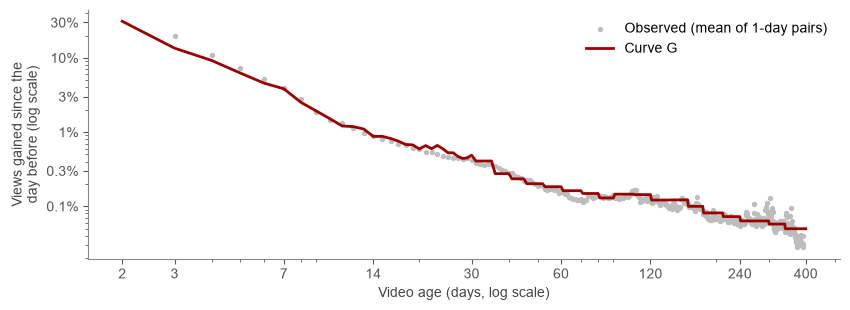

In [9]:
df_shown = df_daily_growth[df_daily_growth["pairs"] >= 100]
fig, ax = plt.subplots(figsize=(8.6, 3.2))
ax.scatter(df_shown["age_days"], df_shown["observed_pct"], s=8, color=GRAY, label="Observed (mean of 1-day pairs)", zorder=2)
ax.plot(df_daily_growth["age_days"], df_daily_growth["curve_pct"], color=RED, linewidth=2, label="Curve G", zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([2, 3, 7, 14, 30, 60, 120, 240, 400])
ax.set_xticklabels(["2", "3", "7", "14", "30", "60", "120", "240", "400"])
ax.set_yticks([0.1, 0.3, 1, 3, 10, 30])
ax.set_yticklabels(["0.1%", "0.3%", "1%", "3%", "10%", "30%"])
ax.set_xlabel("Video age (days, log scale)")
ax.set_ylabel("Views gained since the\nday before (log scale)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/option1_day_after_day.png", dpi=200)
plt.show()

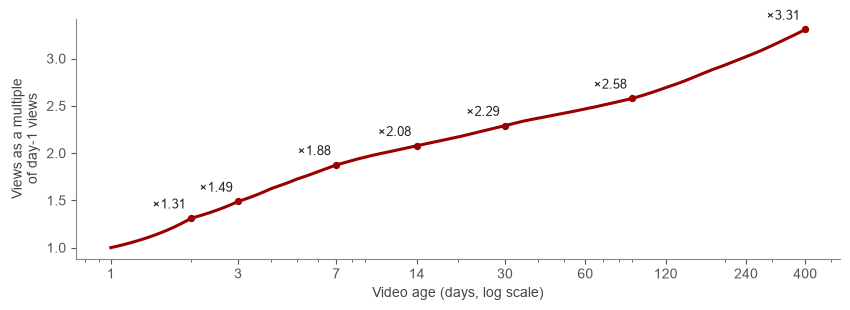

In [10]:
fig, ax = plt.subplots(figsize=(8.6, 3.2))
ages_fine = np.exp(np.linspace(0, np.log(400), 300))
ax.plot(ages_fine, np.exp(G(ages_fine, knot_values)), color=RED, linewidth=2.2)
df_labeled = df_curve[df_curve["age_days"].isin([2, 3, 7, 14, 30, 90, 400])]
ax.scatter(df_labeled["age_days"], df_labeled["multiple_of_day1"], color=RED, s=18, zorder=3)
for _, row in df_labeled.iterrows():
    ax.annotate(f"×{row['multiple_of_day1']:.2f}", (row["age_days"], row["multiple_of_day1"]), textcoords="offset points",
                xytext=(-4, 7), fontsize=9, color=DARK, ha="right")
ax.set_xscale("log")
ax.set_xticks([1, 3, 7, 14, 30, 60, 120, 240, 400])
ax.set_xticklabels(["1", "3", "7", "14", "30", "60", "120", "240", "400"])
ax.set_xlabel("Video age (days, log scale)")
ax.set_ylabel("Views as a multiple\nof day-1 views")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/option1_cumulative_curve.png", dpi=200)
plt.show()

## Normalize every video to day 30

In [11]:
"""Every video's views on SNAPSHOT_DATE moved to day REF_AGE: normalized log views = log views - G(age) + G(REF_AGE).
Videos under 1 day old are left out (the curve starts at day 1)."""
df_latest = df_panel[(df_panel["snapshot_date"] == SNAPSHOT_DATE) & (df_panel["age_days"] >= 1)].copy()
df_latest["lv_normalized"] = df_latest["lv"] - G(df_latest["age_days"], knot_values) + G([REF_AGE], knot_values)[0]
df_latest["views_normalized"] = np.expm1(df_latest["lv_normalized"]).round()
df_latest[["video_id", "channel_title", "age_days", "view_count", "views_normalized", "lv", "lv_normalized"]].to_csv(
    f"{ANALYSIS_DIR}/option1_normalized_videos.csv", index=False)
print(f"{len(df_latest):,} videos normalized")
df_latest[["video_id", "channel_title", "age_days", "view_count", "views_normalized"]].head()

14,027 videos normalized


,video_id,channel_title,age_days,view_count,views_normalized
23,--2mIdgIduE,triple j,105.628270,16413,14251.0
47,--LXDh44cBQ,Mark Rober,141.169739,7238147,6000565.0
71,-009GJ1Lnbc,First We Feast,57.752864,16591,15463.0
95,-0P-MnBJXVI,triple j,65.609855,37577,34563.0
119,-0gM8wliUmo,CarterPCs,394.127425,2294312,1593472.0


In [12]:
"""Check: within a channel, do older videos still have more views after normalizing? Each video's log views minus its
channel's mean, by age band; a flat normalized line means age is out."""
df_latest["age_band"] = pd.cut(df_latest["age_days"], [1, 3, 7, 14, 30, 60, 120, 240, 400])
df_latest["raw_within"] = df_latest["lv"] - df_latest.groupby("channel_id")["lv"].transform("mean")
df_latest["normalized_within"] = df_latest["lv_normalized"] - df_latest.groupby("channel_id")["lv_normalized"].transform("mean")
df_age_trend = df_latest.groupby("age_band", observed=True).agg(videos=("video_id", "size"), raw=("raw_within", "median"),
                                                                normalized=("normalized_within", "median")).reset_index()
print("Slope of within-channel log views on log age: raw",
      round(np.polyfit(np.log(df_latest["age_days"]), df_latest["raw_within"], 1)[0], 3), "| normalized",
      round(np.polyfit(np.log(df_latest["age_days"]), df_latest["normalized_within"], 1)[0], 3))
df_age_trend.head(10)

Slope of within-channel log views on log age: raw 0.026 | normalized -0.12


,age_band,videos,raw,normalized
0,"(1, 3]",89,-0.566192,0.202158
1,"(3, 7]",134,-0.449681,0.073067
2,"(7, 14]",260,-0.115143,0.236009
3,"(14, 30]",589,0.080624,0.309990
4,"(30, 60]",1043,0.072215,0.235769
5,"(60, 120]",2104,-0.030352,0.054073
6,"(120, 240]",4456,-0.080855,-0.095799
7,"(240, 400]",5352,-0.110257,-0.218962


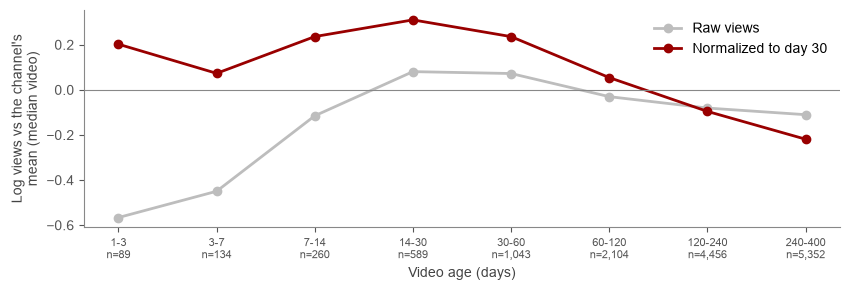

In [13]:
fig, ax = plt.subplots(figsize=(8.6, 3.0))
positions = np.arange(len(df_age_trend))
ax.plot(positions, df_age_trend["raw"], color=GRAY, marker="o", linewidth=2, label="Raw views")
ax.plot(positions, df_age_trend["normalized"], color=RED, marker="o", linewidth=2, label="Normalized to day 30")
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels([f"{band.left:g}-{band.right:g}\nn={n:,}" for band, n in zip(df_age_trend["age_band"], df_age_trend["videos"])], fontsize=8)
ax.set_xlabel("Video age (days)")
ax.set_ylabel("Log views vs the channel's\nmean (median video)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/option1_age_trend.png", dpi=200)
plt.show()

## Evaluation 1: project 14 days ahead

In [14]:
"""Test windows: every video snapshot with a snapshot of the same video exactly HORIZON days later. Projection from the
first: log views + G(age + h) - G(age); baseline: no growth. The curve is refit without the test videos (5 folds by
video) and, separately, without the test channels (5 folds by channel)."""
df_windows = df_panel[["video_id", "channel_id", "snapshot_date", "age_days", "lv"]].merge(
    df_panel[["video_id", "snapshot_date", "age_days", "lv"]].assign(snapshot_date=lambda df: df["snapshot_date"] - pd.Timedelta(days=HORIZON)),
    on=["video_id", "snapshot_date"], suffixes=["_start", "_end"])
df_windows = df_windows[(df_windows["age_days_start"] >= 1) & (df_windows["lv_start"] > 0)].reset_index(drop=True)
df_windows["actual"] = df_windows["lv_end"] - df_windows["lv_start"]
print(f"{len(df_windows):,} test windows from {df_windows['video_id'].nunique():,} videos")
df_windows.head()

131,791 test windows from 13,485 videos


,video_id,channel_id,snapshot_date,age_days_start,lv_start,age_days_end,lv_end,actual
0,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,2026-10-15,76.164365,9.690542,90.582574,9.697508,0.006967
1,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,2026-10-21,82.741719,9.695479,96.624836,9.700392,0.004913
2,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,2026-10-22,83.519212,9.695787,97.635719,9.700820,0.005034
3,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,2026-10-23,84.507278,9.696094,98.611611,9.701494,0.005399
4,--2mIdgIduE,UCd2KNtfphz8HvYzM4pwtHmg,2026-10-24,85.467890,9.696402,99.566391,9.702289,0.005887


In [15]:
channel_ids = df_pairs["channel_id"].unique()
channel_fold = dict(zip(channel_ids, rng.permutation(len(channel_ids)) % N_FOLDS))
pair_channel_fold = df_pairs["channel_id"].map(channel_fold).to_numpy()
window_video_fold = df_windows["video_id"].map(video_fold).fillna(-1).to_numpy()
window_channel_fold = df_windows["channel_id"].map(channel_fold).fillna(-1).to_numpy()
df_windows["held_out_video"] = np.nan
df_windows["held_out_channel"] = np.nan
for fold in range(N_FOLDS):
    knots_video = fit_curve(pair_fold != fold, best_smoothing)
    knots_channel = fit_curve(pair_channel_fold != fold, best_smoothing)
    rows = window_video_fold == fold
    df_windows.loc[rows, "held_out_video"] = G(df_windows.loc[rows, "age_days_end"], knots_video) - G(df_windows.loc[rows, "age_days_start"], knots_video)
    rows = window_channel_fold == fold
    df_windows.loc[rows, "held_out_channel"] = G(df_windows.loc[rows, "age_days_end"], knots_channel) - G(df_windows.loc[rows, "age_days_start"], knots_channel)
df_windows["no_growth"] = 0.0
df_windows["start_band"] = pd.cut(df_windows["age_days_start"], START_AGE_BANDS, right=False)
df_windows[["video_id", "age_days_start", "age_days_end", "actual", "held_out_video", "held_out_channel"]].head()

,video_id,age_days_start,age_days_end,actual,held_out_video,held_out_channel
0,--2mIdgIduE,76.164365,90.582574,0.006967,0.019992,0.016788
1,--2mIdgIduE,82.741719,96.624836,0.004913,0.019138,0.015880
2,--2mIdgIduE,83.519212,97.635719,0.005034,0.019550,0.016204
3,--2mIdgIduE,84.507278,98.611611,0.005399,0.019632,0.016252
4,--2mIdgIduE,85.467890,99.566391,0.005887,0.019720,0.016306


In [16]:
"""Typical error = exp(median |log error|) - 1, as %. Bias = mean signed log error as %: above 0 = over-projects."""
error_rows = []
for band, df_band in [["all", df_windows]] + list(df_windows.groupby("start_band", observed=True)):
    row = {"start_band": str(band), "windows": len(df_band), "videos": df_band["video_id"].nunique()}
    for method in ["no_growth", "held_out_video", "held_out_channel"]:
        error = df_band[method] - df_band["actual"]
        row[f"{method}_error_pct"] = (np.exp(error.abs().median()) - 1) * 100
        row[f"{method}_bias_pct"] = (np.exp(error.mean()) - 1) * 100
    error_rows.append(row)
df_projection = pd.DataFrame(error_rows)
df_projection.to_csv(f"{ANALYSIS_DIR}/option1_projection.csv", index=False)
df_projection.round(2).head(10)

,start_band,windows,videos,no_growth_error_pct,no_growth_bias_pct,held_out_video_error_pct,held_out_video_bias_pct,held_out_channel_error_pct,held_out_channel_bias_pct
0,all,131791,13485,0.35,-2.10,0.98,0.11,1.03,0.12
1,"[1, 3)",687,400,43.85,-37.74,22.26,2.52,22.25,2.45
2,"[3, 7)",1365,587,17.38,-18.86,11.93,2.04,12.11,2.15
3,"[7, 14)",2311,748,8.34,-9.97,6.66,0.74,6.71,0.80
4,"[14, 30)",5603,1071,3.58,-5.74,4.16,0.49,4.23,0.55
5,"[30, 60)",10580,1579,1.39,-2.70,2.06,0.13,2.08,0.14
6,"[60, 120)",20726,2629,0.61,-1.89,1.69,0.07,1.70,0.10
7,"[120, 400)",90519,9322,0.17,-1.02,0.84,0.03,0.88,0.04


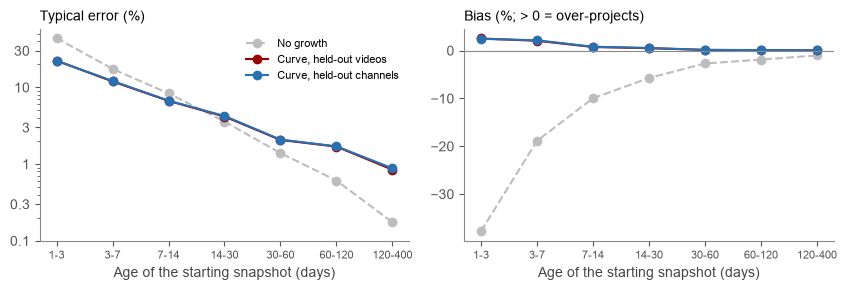

In [17]:
df_bands = df_projection[df_projection["start_band"] != "all"]
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.0))
positions = np.arange(len(df_bands))
labels = [band.replace(", ", "-").strip("[)") for band in df_bands["start_band"]]
for ax, metric, title in [[axes[0], "error", "Typical error (%)"], [axes[1], "bias", "Bias (%; > 0 = over-projects)"]]:
    ax.plot(positions, df_bands[f"no_growth_{metric}_pct"], color=GRAY, marker="o", linestyle="--", label="No growth")
    ax.plot(positions, df_bands[f"held_out_video_{metric}_pct"], color=RED, marker="o", label="Curve, held-out videos")
    ax.plot(positions, df_bands[f"held_out_channel_{metric}_pct"], color="#2A6FB0", marker="o", label="Curve, held-out channels")
    ax.axhline(0, color="#888888", linewidth=0.8)
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlabel("Age of the starting snapshot (days)")
    ax.set_title(title, fontsize=10, loc="left")
axes[0].set_yscale("log")
axes[0].set_yticks([0.1, 0.3, 1, 3, 10, 30])
axes[0].set_yticklabels(["0.1", "0.3", "1", "3", "10", "30"])
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/option1_projection_error.png", dpi=200)
plt.show()

## Evaluation 2: trait signal on the tagged videos

In [18]:
"""Tagged videos (tagged by SNAPSHOT_DATE), their metadata, and their normalized views on SNAPSHOT_DATE. A video tagged
twice keeps its first tags."""
traits = get_traits()
trait_columns = [trait["column"] for trait in traits]
df_tagged = client.query(f"""
WITH tagged AS (SELECT * EXCEPT(tag_rank) FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY id ORDER BY tagged_at) AS tag_rank
                                                FROM youtube.llm_tagged WHERE DATE(tagged_at) <= '{SNAPSHOT_DATE}') WHERE tag_rank = 1)
SELECT {", ".join("t." + column for column in trait_columns)}, t.id AS video_id, v.snippet_publishedAt AS published_at,
       v.snippet_title AS title, v.snippet_description AS description, v.snippet_tags AS tags,
       v.contentDetails_caption AS caption, v.paidProductPlacementDetails_hasPaidProductPlacement AS paid_placement
FROM tagged t
JOIN youtube.videos v ON v.id = t.id
ORDER BY t.id""").to_dataframe().dropna(subset=trait_columns)
df_tagged = df_tagged.merge(df_latest[["video_id", "channel_id", "duration_seconds", "age_days", "lv_normalized"]], on="video_id")
df_tagged = df_tagged[df_tagged["lv_normalized"].notna() & (df_tagged["lv_normalized"] > 0)].reset_index(drop=True)
df_tagged[trait_columns] = df_tagged[trait_columns].astype(float)
trait_columns = [column for column in trait_columns if df_tagged[column].std() > 0]
print(f"{len(df_tagged):,} tagged videos, {df_tagged['channel_id'].nunique()} channels, {len(trait_columns)} traits")
df_tagged[["video_id", "channel_id", "age_days", "lv_normalized"] + trait_columns[:5]].head()

3,061 tagged videos, 51 channels, 79 traits


,video_id,channel_id,age_days,lv_normalized,tutorial,informational,storytelling,reaction,challenge
0,--LXDh44cBQ,UCY1kMZp36IQSyNx_9h4mpCg,141.169739,15.607364,3.0,3.0,2.0,0.0,3.0
1,-1aJc_1YALo,UCoOae5nYA7VqaXzerajD0lg,136.294925,9.885203,0.0,1.0,3.0,0.0,0.0
2,-236J-0Q8FY,UCi7wDE2ZTiR5QYYrUY5WhtA,28.643744,15.333079,0.0,1.0,0.0,1.0,0.0
3,-2jQm1t9pBs,UCV6KDgJskWaEckne5aPA0aQ,92.044809,12.773441,0.0,4.0,1.0,1.0,0.0
4,-376tIX8BBU,UCd2KNtfphz8HvYzM4pwtHmg,28.815689,11.450120,0.0,0.0,0.0,0.0,0.0


In [19]:
"""Video metadata and channel dummies: the base model the traits are added to."""
published_local = df_tagged["published_at"].dt.tz_convert("America/Los_Angeles")
df_meta = pd.DataFrame({
    "log_duration": np.log1p(df_tagged["duration_seconds"].astype(float)),
    "hour_sin": np.sin(2 * np.pi * published_local.dt.hour / 24),
    "hour_cos": np.cos(2 * np.pi * published_local.dt.hour / 24),
    "title_length": df_tagged["title"].fillna("").str.len(),
    "description_length": np.log1p(df_tagged["description"].fillna("").str.len()),
    "n_tags": df_tagged["tags"].fillna("").apply(lambda tags: len([tag for tag in tags.split("|") if tag])),
    "has_caption": (df_tagged["caption"] == "true").astype(float),
    "paid_placement": df_tagged["paid_placement"].fillna(False).astype(float),
    "short": (df_tagged["duration_seconds"] <= SHORTS_MAX_SECONDS).astype(float),
})
df_meta = pd.concat([df_meta, pd.get_dummies(published_local.dt.day_name(), prefix="weekday", drop_first=True, dtype=float)], axis=1)
df_channel = pd.get_dummies(df_tagged["channel_id"], prefix="channel", drop_first=True, dtype=float)
df_base = pd.concat([df_meta, df_channel], axis=1)
df_meta.head()

,log_duration,hour_sin,hour_cos,title_length,description_length,n_tags,has_caption,paid_placement,short,weekday_Monday,weekday_Saturday,weekday_Sunday,weekday_Thursday,weekday_Tuesday,weekday_Wednesday
0,4.477337,1.000000,6.123234e-17,21,0.000000,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,4.394449,0.707107,7.071068e-01,26,4.532599,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,3.367296,-1.000000,-1.836970e-16,34,4.110874,0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,6.933423,0.707107,-7.071068e-01,84,8.515992,22,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,3.663562,-0.500000,-8.660254e-01,58,0.000000,0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [20]:
def cv_r2(df_X, y):
    """Cross-validated R2 (5 folds x N_REPEATS, ridge on standardized columns)."""
    scores = []
    for repeat in range(N_REPEATS):
        predicted = np.zeros(len(y))
        for train, test in KFold(N_FOLDS, shuffle=True, random_state=repeat).split(df_X):
            keep = df_X.columns[df_X.iloc[train].std() > 0]
            scaler = StandardScaler().fit(df_X.iloc[train][keep])
            model = RidgeCV(alphas=ALPHAS).fit(scaler.transform(df_X.iloc[train][keep]), y[train])
            predicted[test] = model.predict(scaler.transform(df_X.iloc[test][keep]))
        scores.append(1 - ((y - predicted) ** 2).sum() / ((y - y.mean()) ** 2).sum())
    return np.mean(scores)


"""Base (metadata + channel) vs base + traits vs base + traits shuffled within channel (mean of N_SHUFFLES). Shuffling keeps
each channel's mix of traits but breaks the link to each video, so only the real-vs-shuffled gap is trait signal."""
y = df_tagged["lv_normalized"].to_numpy()
r2_base = cv_r2(df_base, y)
r2_traits = cv_r2(pd.concat([df_tagged[trait_columns], df_base], axis=1), y)
r2_shuffled = []
for shuffle in range(N_SHUFFLES):
    df_shuffled = df_tagged[trait_columns].copy()
    for channel_rows in df_tagged.groupby("channel_id").indices.values():
        df_shuffled.iloc[channel_rows] = df_shuffled.iloc[rng.permutation(channel_rows)].to_numpy()
    r2_shuffled.append(cv_r2(pd.concat([df_shuffled, df_base], axis=1), y))
df_signal = pd.DataFrame([{"tagged_videos": len(df_tagged), "cv_r2_without_traits": r2_base, "cv_r2_with_traits": r2_traits,
                           "cv_r2_shuffled_traits": np.mean(r2_shuffled), "trait_gain_pps": (r2_traits - r2_base) * 100,
                           "shuffled_gain_pps": (np.mean(r2_shuffled) - r2_base) * 100}])
df_signal.round(4).head()

,tagged_videos,cv_r2_without_traits,cv_r2_with_traits,cv_r2_shuffled_traits,trait_gain_pps,shuffled_gain_pps
0,3061,0.7841,0.7855,0.7767,0.1412,-0.7407


## Summary

In [21]:
"""Option 1 on every metric, in the shape notebooks 09 and 10 will also save."""
row_all = df_projection[df_projection["start_band"] == "all"].iloc[0]
row_young = df_projection[df_projection["start_band"] == "[1, 3)"].iloc[0]
row_old = df_projection[df_projection["start_band"] == "[30, 60)"].iloc[0]
df_metrics = pd.DataFrame([{
    "option": "Option 1: one curve", "snapshot_date": SNAPSHOT_DATE, "videos_normalized": len(df_latest),
    "projection_error_pct_held_out_video": row_all["held_out_video_error_pct"],
    "projection_error_pct_held_out_channel": row_all["held_out_channel_error_pct"],
    "projection_error_pct_no_growth": row_all["no_growth_error_pct"],
    "projection_error_pct_from_day_1_3": row_young["held_out_video_error_pct"],
    "projection_bias_pct_from_day_30_60": row_old["held_out_video_bias_pct"],
    "age_slope_after_normalizing": np.polyfit(np.log(df_latest["age_days"]), df_latest["normalized_within"], 1)[0],
    **df_signal.iloc[0].to_dict()}])
df_metrics.to_csv(f"{ANALYSIS_DIR}/option1_metrics.csv", index=False)
df_metrics.T

,0
option,Option 1: one curve
snapshot_date,2026-11-13
videos_normalized,14027
projection_error_pct_held_out_video,0.980543
projection_error_pct_held_out_channel,1.030845
projection_error_pct_no_growth,0.353263
projection_error_pct_from_day_1_3,22.258525
projection_bias_pct_from_day_30_60,0.132599
age_slope_after_normalizing,-0.119606
tagged_videos,3061.0
